In [33]:
import torch
import soundfile as sf
import numpy as np
import torchaudio
from IPython.display import Audio, display
import matplotlib.pyplot as plt

In [34]:
model, utils = torch.hub.load(repo_or_dir="snakers4/silero-vad", model="silero_vad", force_reload=True, trust_repo=True)

print(f"model: {model}\n")
print(f"utils: {utils}")

Downloading: "https://github.com/snakers4/silero-vad/zipball/master" to /Users/macbook/.cache/torch/hub/master.zip
model: RecursiveScriptModule(
  original_name=VADRNNJITMerge
  (_model): RecursiveScriptModule(
    original_name=VADRNNJIT
    (stft): RecursiveScriptModule(
      original_name=STFT
      (padding): RecursiveScriptModule(original_name=ReflectionPad1d)
    )
    (encoder): RecursiveScriptModule(
      original_name=Sequential
      (0): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (1): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (2): Rec

In [35]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
model.to(device)

RecursiveScriptModule(
  original_name=VADRNNJITMerge
  (_model): RecursiveScriptModule(
    original_name=VADRNNJIT
    (stft): RecursiveScriptModule(
      original_name=STFT
      (padding): RecursiveScriptModule(original_name=ReflectionPad1d)
    )
    (encoder): RecursiveScriptModule(
      original_name=Sequential
      (0): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (1): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (2): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
     

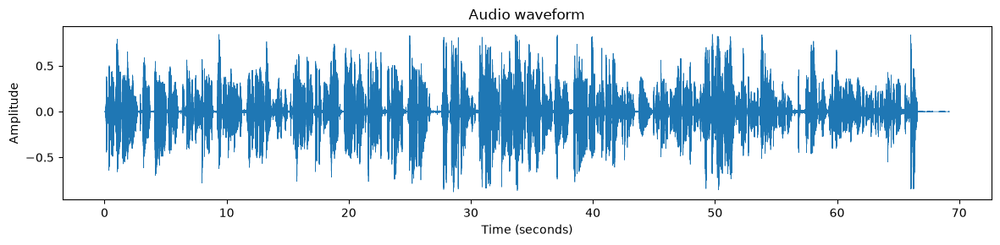

In [36]:
get_speech_timestamps = utils[0]

audio, sr = sf.read("../../data/raw_audios/abuser.wav", dtype="float32", always_2d=True)
wav = torch.from_numpy(audio.T.copy())

target_sr = 48000
if sr != target_sr:
    wav = torchaudio.functional.resample(wav, orig_freq=sr, new_freq=target_sr)
    sr = target_sr

display(Audio(wav.numpy(), rate=sr))

mono = wav.mean(dim=0).numpy()
time = np.arange(len(mono)) / sr

plt.figure(figsize=(12, 3))
plt.plot(time, mono, linewidth=0.5)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio waveform")
plt.tight_layout()
plt.show()